# ECG Heartbeat Data Preparation — Sliding Window Exploration

This notebook walks through how raw PTB-XL ECG records are turned into labelled beat-level samples.

**Two extraction modes are compared:**
1. **R-peak aligned windows** (`use_sliding_window=False`) — positive beats centred on detected R-peaks; negatives from 4 hard-negative strategies.
2. **Dense sliding windows** (`use_sliding_window=True`) — every overlapping window at a fixed stride; label = 1 if the full QT interval is inside the window.

In [66]:
import sys
sys.path.insert(0, "/nfs/data8/schlegel/git/ecg-heartbeat-cbm")

import importlib
import src.data as _data_mod
importlib.reload(_data_mod)

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import wfdb
from pathlib import Path

from src.data import (
    bandpass_filter,
    minmax_normalize,
    delineate_record,
    extract_beats,
    extract_sliding_windows,
    get_concept_labels,
    BEAT_CONCEPT_NAMES,
    PTBXL_ROOT,
)

print("Imports OK")


Imports OK


## 1 — Load one raw PTB-XL record

In [67]:
import pandas as pd

DATA_PATH   = PTBXL_ROOT
SAMPLING_RATE = 500          # Hz
T_FIXED       = 500          # samples per beat window (= 1 s at 500 Hz)
LEAD_IDX      = 0            # lead index for delineation (0 = Lead I)
BEAT_WINDOW_PRE  = 250       # samples before R-peak
BEAT_WINDOW_POST = 250       # samples after  R-peak
STRIDE        = 50           # stride for sliding-window mode

meta = pd.read_csv(DATA_PATH / "ptbxl_database.csv", index_col="ecg_id")

# Find the first fold-1 record that passes the delineation quality check
fold1_ids = meta[meta["strat_fold"] == 1].index.tolist()
ecg_id, row, filename, signal_raw, header = None, None, None, None, None

for candidate_id in fold1_ids[:50]:   # check up to 50 records
    _row = meta.loc[candidate_id]
    _fn  = _row["filename_hr"]
    _sig, _hdr = wfdb.rdsamp(str(DATA_PATH / _fn))
    _sig = _sig.T.astype(np.float32)
    _sig_filt = bandpass_filter(_sig, sampling_rate=SAMPLING_RATE)
    _sig_norm = minmax_normalize(_sig_filt)
    _delin = delineate_record(_sig_norm, sampling_rate=SAMPLING_RATE, lead_idx=LEAD_IDX)
    if _delin["quality_ok"] and len(_delin["r_peaks"]) >= 5:
        ecg_id, row, filename = candidate_id, _row, _fn
        signal_raw, header = _sig, _hdr
        break

if ecg_id is None:
    raise RuntimeError("No suitable record found in first 50 fold-1 records.")

print(f"Record  : {filename}  (ecg_id={ecg_id})")
print(f"Shape   : {signal_raw.shape}   (leads × samples)")
print(f"Duration: {signal_raw.shape[1] / SAMPLING_RATE:.1f} s")


Record  : records500/00000/00035_hr  (ecg_id=35)
Shape   : (12, 5000)   (leads × samples)
Duration: 10.0 s


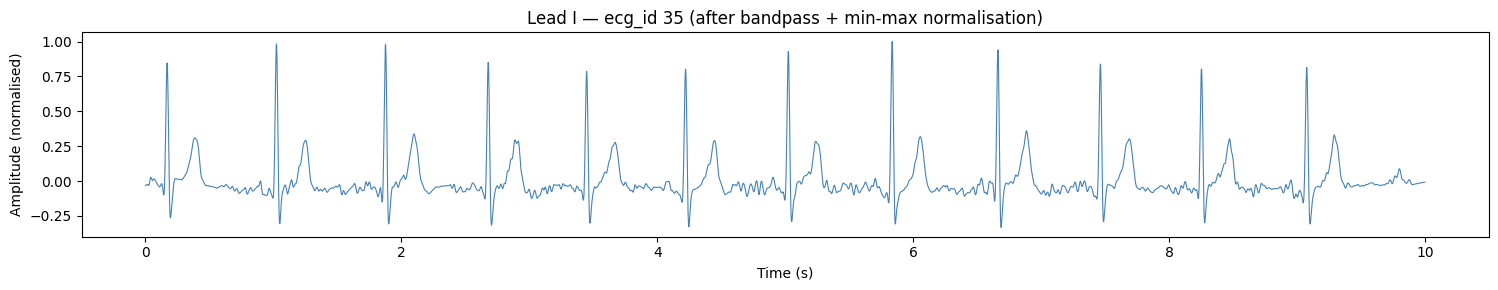

In [68]:
# Preprocess: bandpass filter + min-max normalise
signal_filt = bandpass_filter(signal_raw, sampling_rate=SAMPLING_RATE)
signal      = minmax_normalize(signal_filt)      # (12, 5000)

lead_names = header['sig_name']
t_axis     = np.arange(signal.shape[1]) / SAMPLING_RATE   # seconds

fig, ax = plt.subplots(figsize=(15, 3))
ax.plot(t_axis, signal[LEAD_IDX], color="steelblue", lw=0.8)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (normalised)")
ax.set_title(f"Lead I — ecg_id {ecg_id} (after bandpass + min-max normalisation)")
plt.tight_layout()
plt.show()


## 2 — Delineation: R-peak detection and wave boundary extraction

Multi-lead consensus R-peak detection is used (primary on Lead II, cross-validated across all 12 leads). `neurokit2.ecg_delineate` with the DWT method then finds P, Q, S, T peaks and their on-/offsets.

In [69]:
delin = delineate_record(signal, sampling_rate=SAMPLING_RATE, lead_idx=LEAD_IDX)

r_peaks = delin["r_peaks"]
waves   = delin["delineation"]
u_peaks = delin["u_peaks"]

print(f"Quality OK : {delin['quality_ok']}")
print(f"R-peaks    : {len(r_peaks)} detected")
print(f"RR-interval: min={np.diff(r_peaks).min()} ms, "
      f"max={np.diff(r_peaks).max()} ms, "
      f"mean={np.diff(r_peaks).mean():.1f} ms  (at 500 Hz)")

Quality OK : True
R-peaks    : 12 detected
RR-interval: min=363 ms, max=427 ms, mean=399.0 ms  (at 500 Hz)


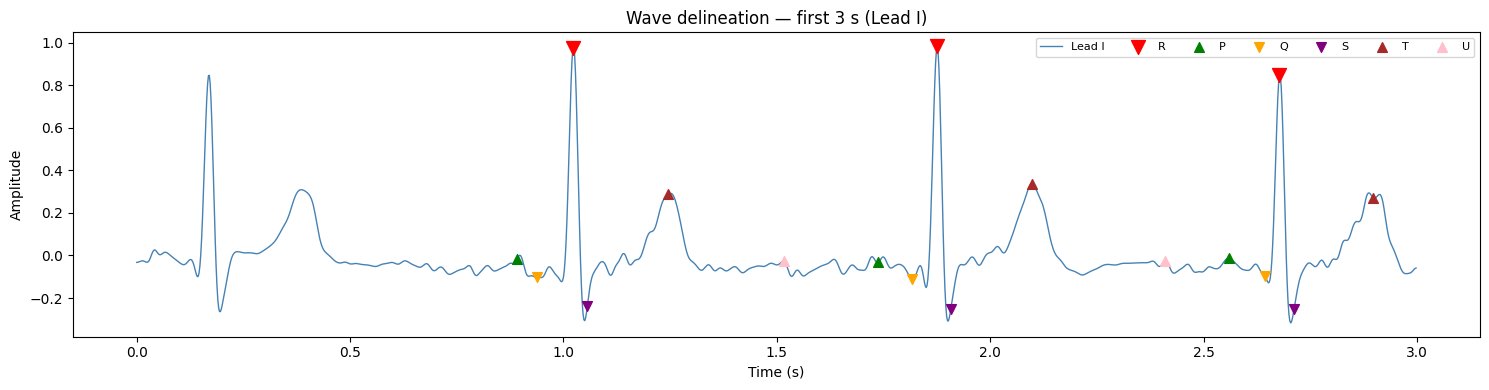

In [70]:
# Plot 3 seconds of Lead I with wave markers overlaid
lead_sig = signal[LEAD_IDX]
t_start, t_end = 0, int(3 * SAMPLING_RATE)    # first 3 s

def _in(arr, lo, hi):
    return [int(v) for v in arr if not np.isnan(v) and lo <= int(v) < hi]

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(t_axis[t_start:t_end], lead_sig[t_start:t_end], color="steelblue", lw=1, label="Lead I")

marker_cfg = {
    "R":  (r_peaks,                           "red",    "v", 10),
    "P":  (waves.get("ECG_P_Peaks",  []),     "green",  "^",  7),
    "Q":  (waves.get("ECG_Q_Peaks",  []),     "orange", "v",  7),
    "S":  (waves.get("ECG_S_Peaks",  []),     "purple", "v",  7),
    "T":  (waves.get("ECG_T_Peaks",  []),     "brown",  "^",  7),
    "U":  (u_peaks,                            "pink",   "^",  7),
}

for label, (indices, color, marker, ms) in marker_cfg.items():
    idxs = _in(indices, t_start, t_end)
    if idxs:
        ax.scatter(t_axis[idxs], lead_sig[idxs], color=color, marker=marker,
                   s=ms**2, zorder=5, label=label)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Wave delineation — first 3 s (Lead I)")
ax.legend(ncol=7, fontsize=8)
plt.tight_layout()
plt.show()


## 3 — Mode A: R-peak aligned beat extraction

Each positive sample is a **500-sample window centred on an R-peak** (250 before, 250 after).  
The natural beat boundary (midpoints to neighbouring R-peaks) determines the **normalisation mask** — only the region inside this boundary contributes to the per-channel mean/std, and the padding is zeroed out.  

Negative samples are generated by four hard-negative strategies:
| Strategy | Description |
|---|---|
| Early truncation | Window that cuts off before the T-wave |
| Late start | Window that misses the P-wave at the front |
| Random crop | Entirely between beats — no R-peak inside |
| Inter-beat | Centred on the midpoint between two R-peaks |

In [71]:
rng    = np.random.default_rng(42)
beats  = extract_beats(
    signal, delin,
    t_fixed=T_FIXED,
    beat_window_pre=BEAT_WINDOW_PRE,
    beat_window_post=BEAT_WINDOW_POST,
    neg_oversample_factor=1.0,
    rng=rng,
)

pos_beats = [(sig, lab, c, w) for sig, lab, c, w in beats if lab == 1]
neg_beats = [(sig, lab, c, w) for sig, lab, c, w in beats if lab == 0]

print(f"Total samples  : {len(beats)}")
print(f"  Positive (1) : {len(pos_beats)}")
print(f"  Negative (0) : {len(neg_beats)}")

Total samples  : 16
  Positive (1) : 10
  Negative (0) : 6


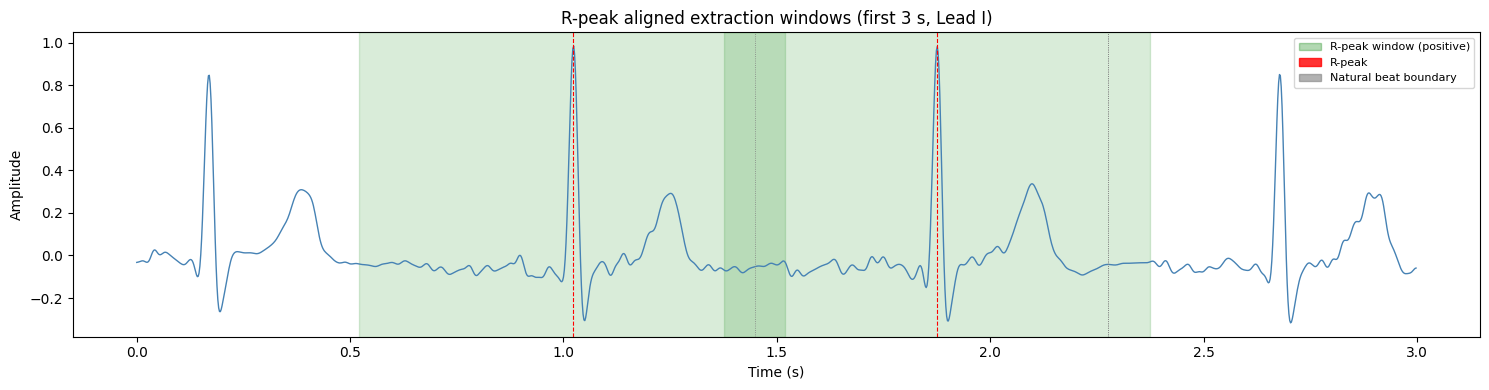

In [72]:
# Visualise the extraction windows on the raw signal (first 3 s)
half_pre  = T_FIXED // 2
half_post = T_FIXED - half_pre

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(t_axis[t_start:t_end], lead_sig[t_start:t_end], color="steelblue", lw=1)

for r in r_peaks:
    start, end = r - half_pre, r + half_post
    if start < t_start or end > t_end:
        continue
    ax.axvspan(t_axis[start], t_axis[end - 1], alpha=0.15, color="green")
    ax.axvline(t_axis[r], color="red", lw=0.8, ls="--")

# Mark natural beat boundaries
for i in range(1, len(r_peaks) - 1):
    r_cur  = int(r_peaks[i])
    r_prev = int(r_peaks[i - 1])
    r_next = int(r_peaks[i + 1])
    bound_l = (r_cur + r_prev) // 2
    bound_r = (r_cur + r_next) // 2
    if t_start <= bound_l < t_end:
        ax.axvline(t_axis[bound_l], color="gray", lw=0.6, ls=":")
    if t_start <= bound_r < t_end:
        ax.axvline(t_axis[bound_r], color="gray", lw=0.6, ls=":")

pos_patch  = mpatches.Patch(color="green",  alpha=0.3,  label="R-peak window (positive)")
rpeak_line = mpatches.Patch(color="red",    alpha=0.8,  label="R-peak")
bound_line = mpatches.Patch(color="gray",   alpha=0.6,  label="Natural beat boundary")
ax.legend(handles=[pos_patch, rpeak_line, bound_line], fontsize=8)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title("R-peak aligned extraction windows (first 3 s, Lead I)")
plt.tight_layout()
plt.show()


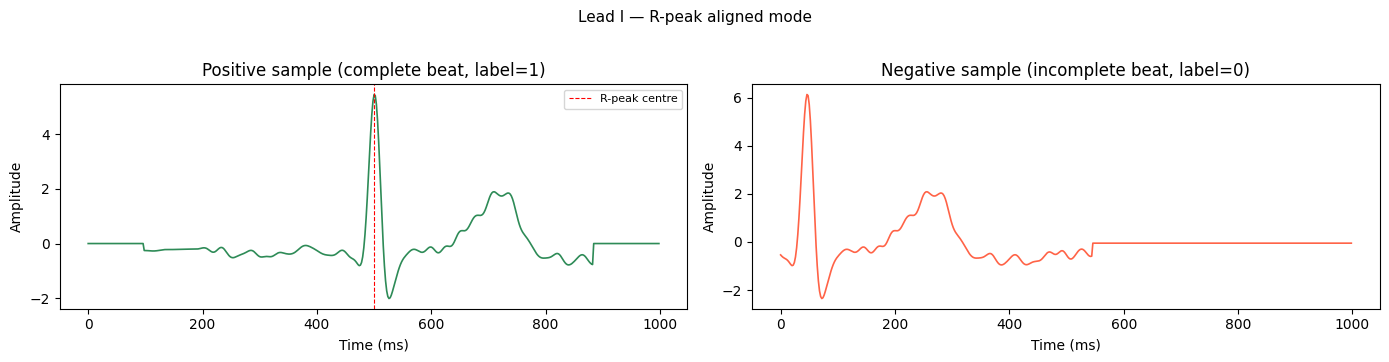

In [73]:
# Show one positive and one negative beat side by side
t_beat = np.arange(T_FIXED) / SAMPLING_RATE * 1000   # ms

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=False)

pos_sig = pos_beats[min(1, len(pos_beats) - 1)][0][LEAD_IDX]
neg_sig = neg_beats[min(3, len(neg_beats) - 1)][0][LEAD_IDX]

axes[0].plot(t_beat, pos_sig, color="seagreen", lw=1.2)
axes[0].set_title("Positive sample (complete beat, label=1)")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("Amplitude")
axes[0].axvline(500, color="red", ls="--", lw=0.8, label="R-peak centre")
axes[0].legend(fontsize=8)

axes[1].plot(t_beat, neg_sig, color="tomato", lw=1.2)
axes[1].set_title("Negative sample (incomplete beat, label=0)")
axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Amplitude")

plt.suptitle("Lead I — R-peak aligned mode", y=1.02, fontsize=11)
plt.tight_layout()
plt.show()


## 4 — Mode B: Dense sliding window extraction

Every window of length `T_FIXED` at stride `STRIDE` is a sample.  
**Label = 1** if a QRS complex lies entirely inside the window (`c_QRS == 1`), since a heartbeat is defined by the presence of a QRS complex.  
This mode produces many more samples and naturally captures various partial-beat configurations.

In [74]:
sw_samples = extract_sliding_windows(
    signal, delin,
    t_fixed=T_FIXED,
    stride=STRIDE,
)

sw_pos = [(sig, lab, c, w) for sig, lab, c, w in sw_samples if lab == 1]
sw_neg = [(sig, lab, c, w) for sig, lab, c, w in sw_samples if lab == 0]

print(f"Total sliding windows : {len(sw_samples)}")
print(f"  Label 1 (complete)  : {len(sw_pos)}  ({100*len(sw_pos)/len(sw_samples):.1f} %)")
print(f"  Label 0 (incomplete): {len(sw_neg)}  ({100*len(sw_neg)/len(sw_samples):.1f} %)")

Total sliding windows : 91
  Label 1 (complete)  : 89  (97.8 %)
  Label 0 (incomplete): 2  (2.2 %)


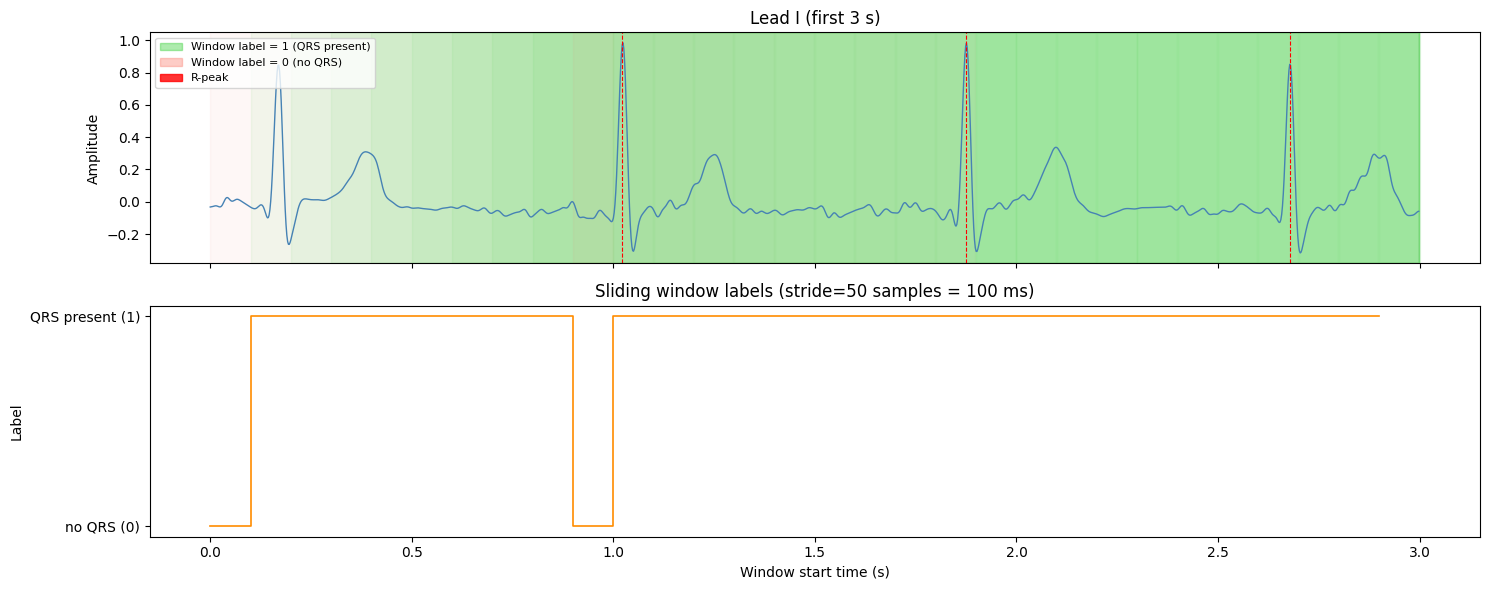

In [75]:
# Visualise sliding window labels on the raw signal (first 3 s)
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)

axes[0].plot(t_axis[t_start:t_end], lead_sig[t_start:t_end], color="steelblue", lw=1)
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Lead I (first 3 s)")

# Build a per-sample label array for the coloured label bar
n_windows = len(sw_samples)
win_labels = np.array([lab for _, lab, _, _ in sw_samples])
win_starts = np.arange(0, signal.shape[1] - T_FIXED + 1, STRIDE)

# Shaded spans for positive windows in the first 3 s
for start, lab in zip(win_starts, win_labels):
    end = start + T_FIXED
    if start > t_end:
        break
    if end < t_start:
        continue
    color = "limegreen" if lab == 1 else "salmon"
    axes[0].axvspan(t_axis[max(start, t_start)], t_axis[min(end - 1, t_end - 1)],
                    alpha=0.06, color=color)

for r in r_peaks:
    if t_start <= r < t_end:
        axes[0].axvline(t_axis[r], color="red", lw=0.8, ls="--")

green_p = mpatches.Patch(color="limegreen", alpha=0.4, label="Window label = 1 (QRS present)")
red_p   = mpatches.Patch(color="salmon",    alpha=0.4, label="Window label = 0 (no QRS)")
r_line  = mpatches.Patch(color="red",       alpha=0.8, label="R-peak")
axes[0].legend(handles=[green_p, red_p, r_line], fontsize=8)

# Bottom panel: label timeline
vis_mask = win_starts < t_end
axes[1].step(t_axis[win_starts[vis_mask]], win_labels[vis_mask],
             where="post", color="darkorange", lw=1.2)
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["no QRS (0)", "QRS present (1)"])
axes[1].set_xlabel("Window start time (s)")
axes[1].set_ylabel("Label")
axes[1].set_title(f"Sliding window labels (stride={STRIDE} samples = {STRIDE/SAMPLING_RATE*1000:.0f} ms)")

plt.tight_layout()
plt.show()


## 5 — Concept labels

Each sample carries a 10-dimensional binary concept vector `[P, Q, R, S, T, U, PR, QRS, ST, QT]`.  
A concept is **1** if the corresponding wave/interval lies within the extraction window, **0** otherwise.  
A companion weight vector marks which concepts the delineation actually found (0 = delineation failed; treat as unknown).

In [76]:
print(f"Concept names : {BEAT_CONCEPT_NAMES}")
print()
print("── 3 positive beats ──")
for i, (_, lab, c, w) in enumerate(pos_beats[:3]):
    print(f"  Beat {i+1}: label={lab}  concepts={c}  weights={w}")

print()
print("── 3 negative beats ──")
for i, (_, lab, c, w) in enumerate(neg_beats[:3]):
    print(f"  Beat {i+1}: label={lab}  concepts={c}  weights={w}")

Concept names : ['P', 'Q', 'R', 'S', 'T', 'U', 'PR', 'QRS', 'ST', 'QT']

── 3 positive beats ──
  Beat 1: label=1  concepts=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]  weights=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  Beat 2: label=1  concepts=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]  weights=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  Beat 3: label=1  concepts=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]  weights=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

── 3 negative beats ──
  Beat 1: label=0  concepts=[1, 1, 1, 1, 0, 1, 1, 1, 0, 0]  weights=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  Beat 2: label=0  concepts=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]  weights=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  Beat 3: label=0  concepts=[1, 1, 1, 1, 1, 0, 1, 1, 1, 1]  weights=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


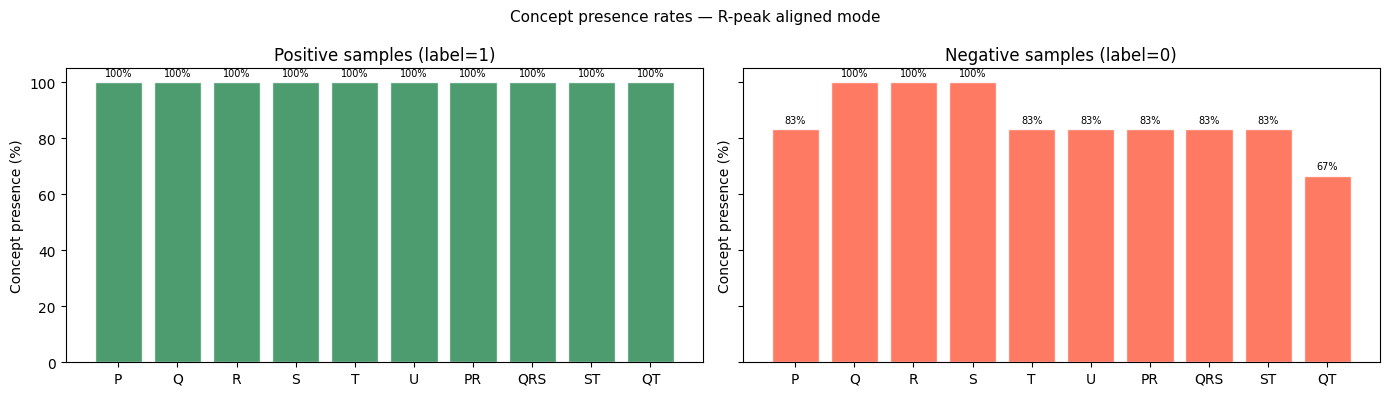

In [77]:
# Concept presence rate across all R-peak-aligned samples
concepts_all = np.array([c for _, _, c, _ in beats])   # (N, 10)
weights_all  = np.array([w for _, _, _, w in beats])   # (N, 10)

pos_mask = np.array([lab for _, lab, _, _ in beats]) == 1
neg_mask = ~pos_mask

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, mask, title, color in [
    (axes[0], pos_mask, "Positive samples (label=1)", "seagreen"),
    (axes[1], neg_mask, "Negative samples (label=0)", "tomato"),
]:
    sub = concepts_all[mask]
    rates = sub.mean(axis=0) * 100
    ax.bar(BEAT_CONCEPT_NAMES, rates, color=color, edgecolor="white", alpha=0.85)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Concept presence (%)")
    ax.set_title(title)
    for j, v in enumerate(rates):
        ax.text(j, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", fontsize=7)

plt.suptitle("Concept presence rates — R-peak aligned mode", fontsize=11)
plt.tight_layout()
plt.show()

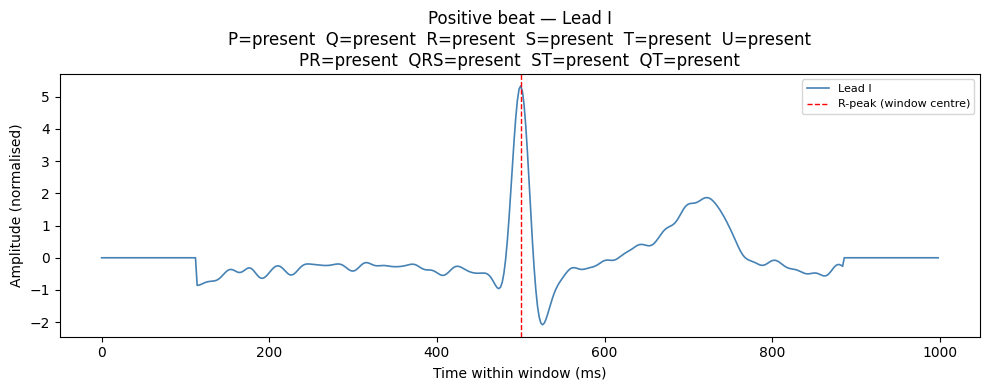

In [78]:
# Show one positive beat with annotated wave components (Lead I)
beat_sig, _, beat_concepts, beat_weights = pos_beats[2]
lead_sig_beat = beat_sig[LEAD_IDX]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_beat, lead_sig_beat, color="steelblue", lw=1.2, label="Lead I")

# Mark R-peak centre
ax.axvline(500, color="red", ls="--", lw=1, label="R-peak (window centre)")

concept_labels_text = [
    f"{name}={'present' if val else 'absent'}"
    for name, val in zip(BEAT_CONCEPT_NAMES, beat_concepts)
]
ax.set_title(f"Positive beat — Lead I\n" + "  ".join(concept_labels_text[:6]) + "\n" + "  ".join(concept_labels_text[6:]))
ax.set_xlabel("Time within window (ms)")
ax.set_ylabel("Amplitude (normalised)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


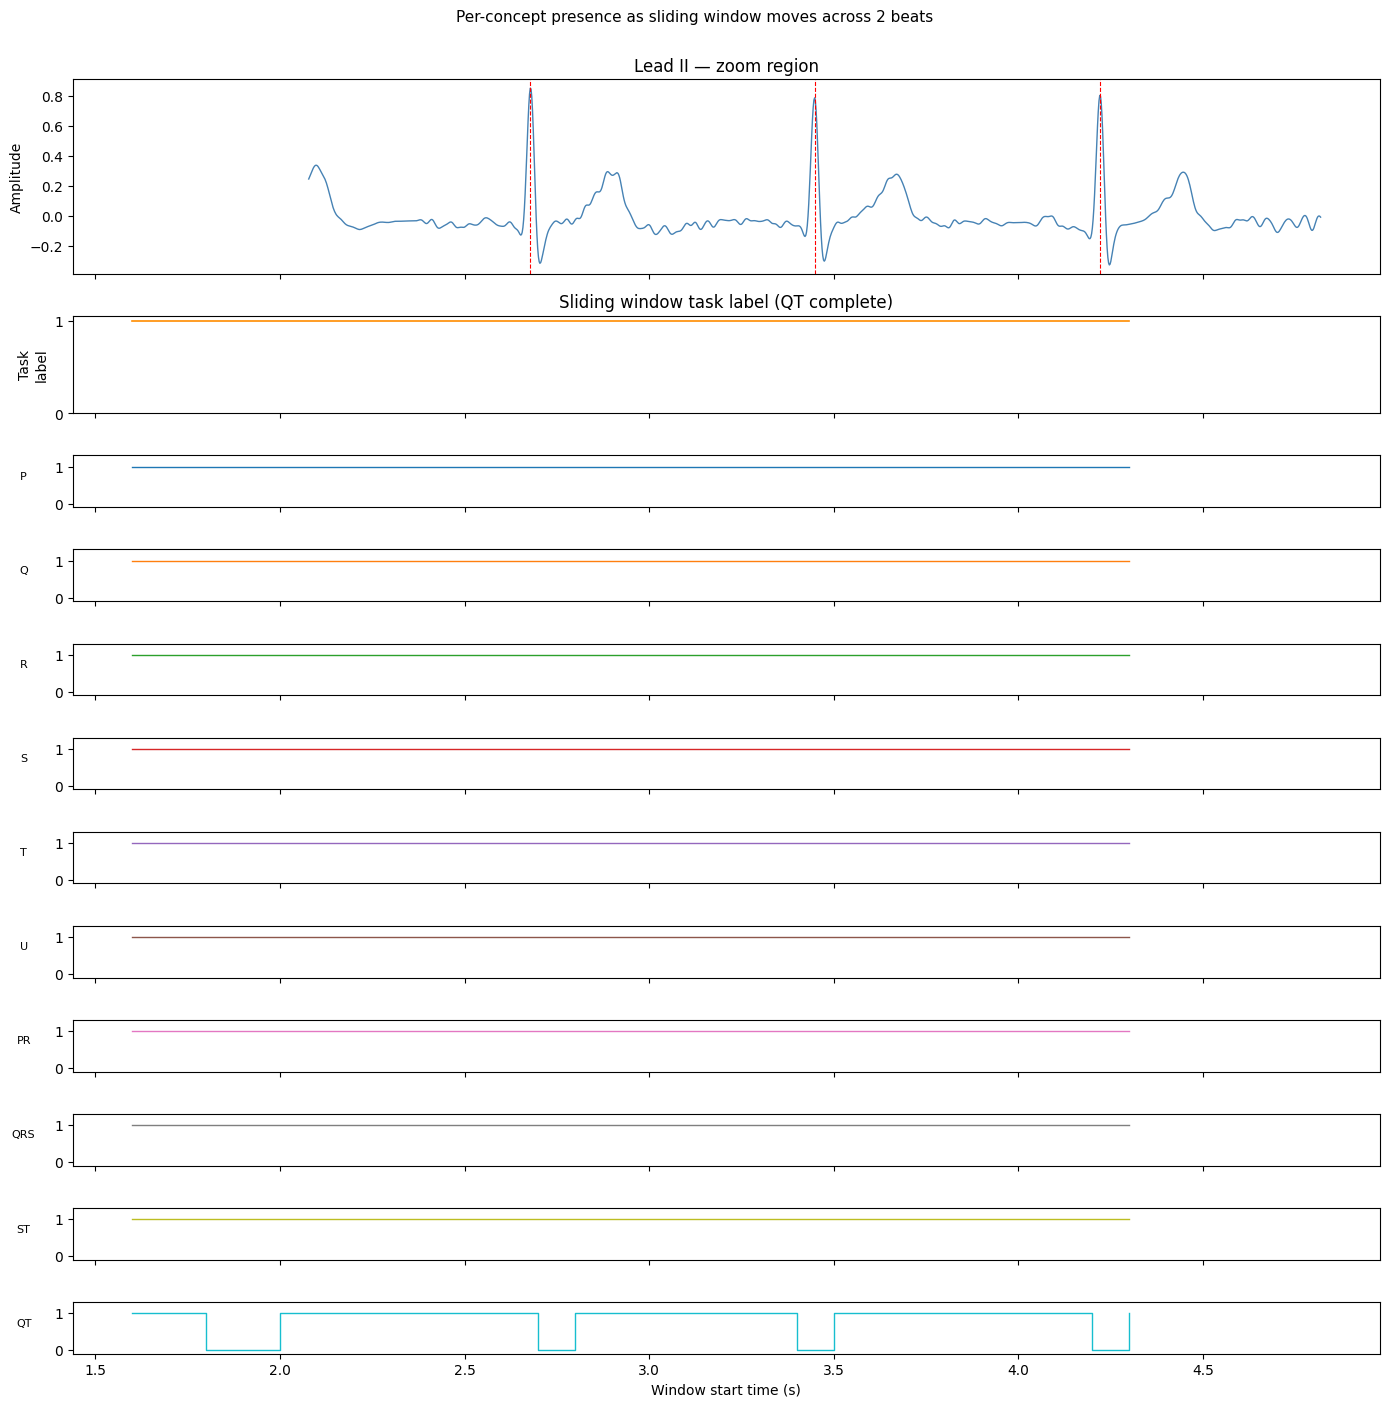

In [79]:
# Sliding window: how concepts evolve as the window moves across a single beat
# Show a zoomed region (2-beat segment) together with per-concept label timelines

t2_start = int(r_peaks[2]) - 300
t2_end   = int(r_peaks[4]) + 300

# Gather windows whose centre falls in our zoom region
zoom_wins = [
    (start, lab, c, w)
    for (start, (_, lab, c, w)) in zip(win_starts, sw_samples)
    if t2_start <= start + T_FIXED // 2 <= t2_end
]

if zoom_wins:
    starts_z  = np.array([z[0] for z in zoom_wins])
    labels_z  = np.array([z[1] for z in zoom_wins])
    concepts_z = np.array([z[2] for z in zoom_wins])  # (M, 10)

    fig, axes = plt.subplots(
        len(BEAT_CONCEPT_NAMES) + 2, 1,
        figsize=(14, 14),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1.5] + [0.8] * len(BEAT_CONCEPT_NAMES)},
    )

    # Top: raw signal
    t_z = t_axis[t2_start:t2_end]
    axes[0].plot(t_z, lead_sig[t2_start:t2_end], color="steelblue", lw=1)
    for r in r_peaks:
        if t2_start <= r < t2_end:
            axes[0].axvline(t_axis[r], color="red", lw=0.8, ls="--")
    axes[0].set_ylabel("Amplitude")
    axes[0].set_title("Lead II — zoom region")

    # Task label timeline
    axes[1].step(t_axis[starts_z], labels_z, where="post", color="darkorange", lw=1.2)
    axes[1].set_yticks([0, 1])
    axes[1].set_ylabel("Task\nlabel")
    axes[1].set_title("Sliding window task label (QT complete)")

    # Per-concept timelines
    colors_c = plt.cm.tab10(np.linspace(0, 1, len(BEAT_CONCEPT_NAMES)))
    for j, (name, color) in enumerate(zip(BEAT_CONCEPT_NAMES, colors_c)):
        axes[j + 2].step(t_axis[starts_z], concepts_z[:, j], where="post",
                         color=color, lw=1)
        axes[j + 2].set_yticks([0, 1])
        axes[j + 2].set_ylabel(name, rotation=0, labelpad=22, fontsize=8)
        axes[j + 2].set_ylim(-0.1, 1.3)

    axes[-1].set_xlabel("Window start time (s)")
    plt.suptitle("Per-concept presence as sliding window moves across 2 beats", y=1.002, fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print("No windows found in zoom region — try a different record.")

## 6 — Summary: comparison of the two extraction modes

In [80]:
import pandas as pd

summary = pd.DataFrame({
    "Mode": ["R-peak aligned", "Sliding window"],
    "Total samples": [len(beats), len(sw_samples)],
    "Positives (label=1)": [len(pos_beats), len(sw_pos)],
    "Negatives (label=0)": [len(neg_beats), len(sw_neg)],
    "Pos ratio (%)": [
        f"{100*len(pos_beats)/len(beats):.1f}",
        f"{100*len(sw_pos)/len(sw_samples):.1f}",
    ],
    "Window size (samples)": [T_FIXED, T_FIXED],
    "Stride": ["N/A (R-peak centred)", str(STRIDE)],
    "Label criterion": ["R-peak inside window", "QRS complex inside window"],
})

summary.set_index("Mode", inplace=True)
summary


,Total samples,Positives (label=1),Negatives (label=0),Pos ratio (%),Window size (samples),Stride,Label criterion
Mode,,,,,,,
R-peak aligned,16,10,6,62.5,500,N/A (R-peak centred),R-peak inside window
Sliding window,91,89,2,97.8,500,50,QRS complex inside window
